# Assignment No. 2: Data Cleaning and Preprocessing

## Introduction

Data cleaning and preprocessing are important steps in data science. Raw data may contain missing values, duplicate records, incorrect data types, inconsistent categories, and outliers.

In this assignment, the Titanic dataset from Kaggle is used to perform data cleaning and preprocessing. The objective is to prepare reliable data for further analysis and machine learning.

**Main objectives:**
- Identify and handle missing values.
- Detect and remove duplicate records.
- Correct inconsistent values and data types.
- Identify and examine outliers.
- Identify numerical, categorical, binary, ordinal, and date/time variables.
- Apply encoding, scaling, and transformation.
- Create useful new features.
- Prevent data leakage during preprocessing.

In [1]:
# Problem: We need tools for data cleaning, visualization, and preprocessing.
# Solution: Import the required Python libraries.

import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression

print("All libraries imported successfully.")

All libraries imported successfully.


## 1. Dataset Description

**Dataset title:** Titanic - Machine Learning from Disaster

**Source:** Kaggle

**Dataset link:** https://www.kaggle.com/c/titanic/data

**Number of rows and columns:** The training dataset contains 891 rows and 12 columns before cleaning.

**Objective:** The dataset contains passenger information such as age, sex, ticket class, fare, and family members. The objective is to study the data and prepare it for predicting whether a passenger survived the Titanic disaster.

**Main columns:**
- `PassengerId`: Unique passenger identifier.
- `Survived`: Target variable; 0 means did not survive and 1 means survived.
- `Pclass`: Passenger ticket class.
- `Name`: Passenger name.
- `Sex`: Passenger sex.
- `Age`: Passenger age.
- `SibSp`: Number of siblings and spouses aboard.
- `Parch`: Number of parents and children aboard.
- `Ticket`: Ticket number.
- `Fare`: Ticket fare.
- `Cabin`: Cabin information.
- `Embarked`: Port where the passenger boarded.

In [5]:
# Problem: The dataset path may be different in Kaggle.
# Solution: Search the input folders to find train.csv automatically.

import os
import pandas as pd

dataset_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    if "train.csv" in files:
        dataset_path = os.path.join(root, "train.csv")
        break

if dataset_path is None:
    raise FileNotFoundError(
        "train.csv not found. Please add the Titanic dataset "
        "using the Add Input option in Kaggle."
    )

df = pd.read_csv(dataset_path)

# Save an unchanged backup.
os.makedirs("/kaggle/working", exist_ok=True)

df.to_csv(
    "/kaggle/working/titanic_original_backup.csv",
    index=False
)

print("Dataset path:", dataset_path)
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset path: /kaggle/input/datasets/jhankhan/titanic-machine-learning-from-disaster/train.csv
Dataset loaded successfully!
Number of rows and columns: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Initial Data Inspection

**Problem:** Before cleaning the dataset, we need to understand its structure, data types, missing values, and duplicate records.

**Solution:** We will use `info()`, `describe()`, and missing-value counts to inspect the data.

This step helps us decide which columns need cleaning and which preprocessing methods are appropriate.

In [6]:
# Problem: Data quality issues cannot be handled properly without inspection.
# Solution: Display the dataset structure, statistics, missing values, and duplicates.

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe())

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (891, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Numerical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Missing values in each column:


,Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



Exact duplicate rows: 0

First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Duplicate Record Removal

**Problem:** Duplicate rows can cause the same information to be counted more than once.

**Solution:** We will remove exact duplicate rows and check whether `PassengerId` contains duplicates.

Passenger IDs should be unique. However, records with repeated IDs will be investigated rather than deleted blindly.

In [7]:
# Problem: Duplicate records can affect analysis.
# Solution: Remove exact duplicates and inspect repeated passenger IDs.

rows_before = len(df)

df = df.drop_duplicates().copy()

print("Exact duplicate rows removed:", rows_before - len(df))

print(
    "Duplicate PassengerId values:",
    df["PassengerId"].duplicated().sum()
)

if df["PassengerId"].duplicated().any():
    display(
        df[df["PassengerId"].duplicated(keep=False)]
        .sort_values("PassengerId")
    )
else:
    print("All PassengerId values are unique.")

Exact duplicate rows removed: 0
Duplicate PassengerId values: 0
All PassengerId values are unique.


## 4. Correct Inconsistent Values and Data Types

**Problem:** Text values may have unnecessary spaces or inconsistent capitalization. Some columns may also have incorrect data types.

**Solution:** We will standardize text, convert numeric columns into suitable data types, and check the resulting values.

This makes the data more consistent and easier to analyze.

In [8]:
# Problem: Inconsistent formatting and data types can cause errors.
# Solution: Standardize text and convert numerical columns safely.

text_columns = ["Name", "Sex", "Ticket", "Cabin", "Embarked"]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Standardize categorical values.
df["Sex"] = df["Sex"].str.lower()
df["Embarked"] = df["Embarked"].str.upper()

# Convert numerical columns.
numeric_columns = [
    "PassengerId", "Survived", "Pclass",
    "Age", "SibSp", "Parch", "Fare"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert ID, target, class, and count columns to nullable integers.
integer_columns = [
    "PassengerId", "Survived", "Pclass", "SibSp", "Parch"
]

for col in integer_columns:
    df[col] = df[col].astype("Int64")

print("Corrected data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nSex categories:", df["Sex"].dropna().unique())
print("Embarked categories:", df["Embarked"].dropna().unique())

Corrected data types:


,Data Type
PassengerId,Int64
Survived,Int64
Pclass,Int64
Name,string[python]
Sex,string[python]
Age,float64
SibSp,Int64
Parch,Int64
Ticket,string[python]
Fare,float64



Sex categories: <StringArray>
['male', 'female']
Length: 2, dtype: string
Embarked categories: <StringArray>
['S', 'C', 'Q']
Length: 3, dtype: string


## 5. Validation of Data Values

**Problem:** Invalid categories, negative ages, negative fares, or impossible passenger counts can reduce data quality.

**Solution:** We will identify invalid values and replace them with missing values. Rows with invalid survival labels will be removed because the target must contain only 0 or 1.

In [9]:
# Problem: Invalid values can produce unreliable results.
# Solution: Validate categories and replace impossible values with missing data.

df.loc[~df["Sex"].isin(["male", "female"]), "Sex"] = pd.NA
df.loc[~df["Embarked"].isin(["S", "C", "Q"]), "Embarked"] = pd.NA
df.loc[~df["Pclass"].isin([1, 2, 3]), "Pclass"] = pd.NA

# Negative ages and fares are invalid.
df.loc[df["Age"] < 0, "Age"] = np.nan
df.loc[df["Fare"] < 0, "Fare"] = np.nan

# Negative family counts are invalid.
df.loc[df["SibSp"] < 0, "SibSp"] = pd.NA
df.loc[df["Parch"] < 0, "Parch"] = pd.NA

# Keep only valid target labels.
df = df[df["Survived"].isin([0, 1])].copy()
df["Survived"] = df["Survived"].astype(int)

print("Rows after validation:", len(df))
print("\nMissing values after validation:")
display(df.isnull().sum().to_frame("Missing Values"))

Rows after validation: 891

Missing values after validation:


,Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


## 6. Missing Value Analysis

**Problem:** The dataset contains missing values, particularly in `Age`, `Cabin`, and `Embarked`.

**Solution:** First, calculate the missing-value count and percentage. Then extract the first letter of `Cabin` as a new feature called `Deck`. Since many cabin values are missing, the original `Cabin` column will be removed.

Missing numerical and categorical feature values will be imputed later using a pipeline fitted only on the training data. This prevents data leakage.

In [10]:
# Problem: Missing values need to be identified and handled appropriately.
# Solution: Measure missingness and preserve useful cabin information.

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

# Extract the cabin deck letter.
df["Deck"] = df["Cabin"].str[0].str.upper()

# Represent missing cabin information as an explicit category.
df["Deck"] = df["Deck"].fillna("Unknown")

# Remove the original cabin column.
df.drop(columns=["Cabin"], inplace=True)

print("Cabin column removed.")
print("\nDeck categories:")
print(df["Deck"].value_counts())

,Missing Count,Missing Percentage
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


Cabin column removed.

Deck categories:
Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: Int64


## 7. Outlier Detection

**Problem:** Some passengers have unusually high fares or ages compared with other passengers.

**Solution:** We will use the Interquartile Range (IQR) method and boxplots to identify possible outliers.

The IQR method identifies values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. Such values will be investigated rather than automatically deleted because they may be genuine observations.


Column: Age
Lower boundary: -6.69
Upper boundary: 64.81
Possible outlier count: 11


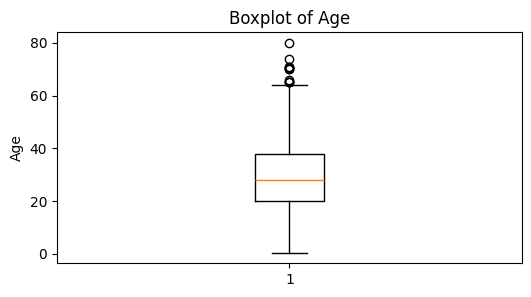


Column: Fare
Lower boundary: -26.72
Upper boundary: 65.63
Possible outlier count: 116


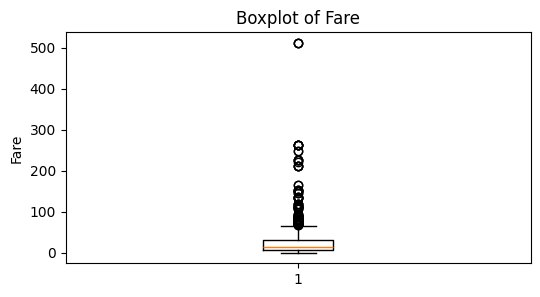

In [11]:
# Problem: Extreme numerical values may affect statistical analysis.
# Solution: Detect possible outliers using the IQR method.

def detect_outliers(series):
    series = series.dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = series[(series < lower) | (series > upper)]

    return lower, upper, outliers

for col in ["Age", "Fare"]:
    lower, upper, outliers = detect_outliers(df[col])

    print(f"\nColumn: {col}")
    print("Lower boundary:", round(lower, 2))
    print("Upper boundary:", round(upper, 2))
    print("Possible outlier count:", len(outliers))

    plt.figure(figsize=(6, 3))
    plt.boxplot(df[col].dropna())
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)
    plt.show()

## 8. Numerical Transformation

**Problem:** The `Fare` variable may be right-skewed because a small number of passengers paid much higher fares.

**Solution:** We will examine its skewness and apply `log1p`, which calculates log(1 + Fare). This transformation can reduce the influence of large values and also supports a fare of zero.

Skewness before: 4.787
Skewness after: 0.395


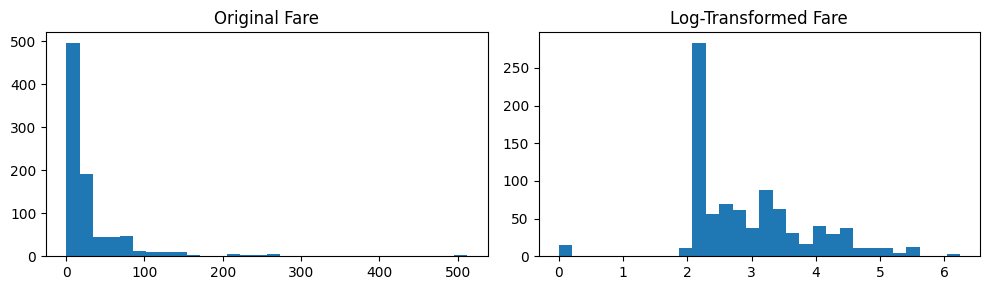

In [12]:
# Problem: A strongly skewed Fare feature may affect analysis.
# Solution: Compare the original distribution with a log transformation.

fare_skew_before = df["Fare"].skew()

df["Fare_log"] = np.log1p(df["Fare"])

fare_skew_after = df["Fare_log"].skew()

print("Skewness before:", round(fare_skew_before, 3))
print("Skewness after:", round(fare_skew_after, 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].hist(df["Fare"].dropna(), bins=30)
axes[0].set_title("Original Fare")

axes[1].hist(df["Fare_log"].dropna(), bins=30)
axes[1].set_title("Log-Transformed Fare")

plt.tight_layout()
plt.show()

## 9. Feature Engineering

**Problem:** Some useful information is not directly available as a separate column.

**Solution:** We will create three features:
- `FamilySize`: Total number of people in the passenger's listed family group, including the passenger.
- `IsAlone`: Indicates whether the passenger travelled without listed family members.
- `Title`: Extracts a title such as Mr, Mrs, Miss, or Master from the passenger's name.

These features may help reveal patterns in passenger survival.

In [13]:
# Problem: Existing columns may hide useful information.
# Solution: Create additional features from existing columns.

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Extract titles from passenger names.
df["Title"] = df["Name"].str.extract(
    r",\s*([^.]*)\.",
    expand=False
)

df["Title"] = df["Title"].str.strip().str.title()

# Group uncommon titles.
common_titles = ["Mr", "Mrs", "Miss", "Master"]

df["Title"] = df["Title"].where(
    df["Title"].isin(common_titles),
    "Other"
)

print("Feature engineering completed.")

display(df[[
    "Name", "Title", "SibSp", "Parch",
    "FamilySize", "IsAlone"
]].head(10))

Feature engineering completed.


,Name,Title,SibSp,Parch,FamilySize,IsAlone
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,1,0,2,0
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0
4,"Allen, Mr. William Henry",Mr,0,0,1,1
5,"Moran, Mr. James",Mr,0,0,1,1
6,"McCarthy, Mr. Timothy J",Mr,0,0,1,1
7,"Palsson, Master. Gosta Leonard",Master,3,1,5,0
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs,0,2,3,0
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs,1,0,2,0


## 10. Save the Cleaned Dataset

**Problem:** We need to preserve the results of data cleaning before beginning preprocessing.

**Solution:** Save the cleaned dataset as a CSV file in Kaggle's working directory. This file will contain the cleaned columns and engineered features.

In [14]:
# Problem: Cleaning results should be saved for reuse.
# Solution: Export the cleaned dataset as a CSV file.

cleaned_path = "/kaggle/working/titanic_cleaned.csv"

df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved to:", cleaned_path)
print("Cleaned dataset shape:", df.shape)

display(df.head())

Cleaned dataset saved to: /kaggle/working/titanic_cleaned.csv
Cleaned dataset shape: (891, 16)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck,Fare_log,FamilySize,IsAlone,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Unknown,2.110213,2,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,4.280593,2,0,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Unknown,2.188856,1,1,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,C,3.990834,2,0,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Unknown,2.202765,1,1,Mr


## 11. Identification of Variable Types

Different variables require different preprocessing methods.

- **Numerical:** Age, Fare_log, SibSp, Parch, FamilySize.
- **Categorical:** Sex, Embarked, Deck, Title.
- **Binary:** Survived and IsAlone.
- **Ordinal:** Pclass, because it has three ordered classes.
- **Date/Time:** There are no date or time columns in this dataset.

PassengerId is an identifier, while Name and Ticket are descriptive columns. They will not be used as model inputs.

In [15]:
# Problem: The target must be separated from the input features.
# Solution: Use Survived as the target and select the useful features.

X = df.drop(
    columns=["Survived", "PassengerId", "Name", "Ticket", "Fare"]
).copy()

y = df["Survived"].copy()

numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "FamilySize",
    "IsAlone",
    "Fare_log"
]

categorical_features = [
    "Sex",
    "Embarked",
    "Deck",
    "Title"
]

print("Input features:", X.shape)
print("Target:", y.shape)

display(X.head())

Input features: (891, 11)
Target: (891,)


,Pclass,Sex,Age,SibSp,Parch,Embarked,Deck,Fare_log,FamilySize,IsAlone,Title
0,3,male,22.0,1,0,S,Unknown,2.110213,2,0,Mr
1,1,female,38.0,1,0,C,C,4.280593,2,0,Mrs
2,3,female,26.0,0,0,S,Unknown,2.188856,1,1,Miss
3,1,female,35.0,1,0,S,C,3.990834,2,0,Mrs
4,3,male,35.0,0,0,S,Unknown,2.202765,1,1,Mr


## 12. Train-Validation Split

**Problem:** Preprocessing the complete dataset before splitting can cause data leakage.

**Solution:** Divide the data into training and validation sets first. The training set will be used to learn preprocessing parameters, while the validation set will be used to check the results.

In [16]:
# Problem: We must avoid data leakage.
# Solution: Split the data before fitting preprocessing methods.

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Training rows: 712
Validation rows: 179


## 13. Encoding and Scaling

**Problem:** Machine learning algorithms cannot directly use missing values and categorical text.

**Solution:** Fill missing numerical values using the median, fill missing categorical values using the most frequent value, encode categories using One-Hot Encoding, and standardize numerical features using StandardScaler.

The preprocessing methods will be fitted only on the training data to prevent data leakage.

In [19]:

# Problem: Scikit-learn cannot properly process some pd.NA values.
# Solution: Convert missing values to NumPy NaN before preprocessing.

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Make copies so the original training and validation data stay unchanged.
X_train = X_train.copy()
X_val = X_val.copy()

# Convert numerical columns to standard numeric types.
for col in numeric_features:
    X_train[col] = pd.to_numeric(
        X_train[col], errors="coerce"
    ).astype(float)

    X_val[col] = pd.to_numeric(
        X_val[col], errors="coerce"
    ).astype(float)

# Convert categorical columns to regular strings and standard NaN.
for col in categorical_features:
    X_train[col] = X_train[col].astype(object)
    X_val[col] = X_val[col].astype(object)

    X_train[col] = X_train[col].where(
        X_train[col].notna(), np.nan
    )
    X_val[col] = X_val[col].where(
        X_val[col].notna(), np.nan
    )

# Numerical preprocessing: fill missing values and scale.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: fill missing values and encode categories.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each group of columns.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit using training data only.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation data.
X_val_processed = preprocessor.transform(X_val)

print("Training data processed:", X_train_processed.shape)
print("Validation data processed:", X_val_processed.shape)
print("Preprocessing completed successfully!")


Training data processed: (712, 26)
Validation data processed: (179, 26)
Preprocessing completed successfully!


### Converting Processed Data into a DataFrame

After preprocessing, the data is converted into DataFrames so it can be displayed in a proper table. This makes it easier to understand the transformed features and check the results of preprocessing.

In [20]:

# Convert processed data into DataFrames for easy viewing.

feature_names = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_val_df = pd.DataFrame(
    X_val_processed,
    columns=feature_names,
    index=X_val.index
)

print("Processed training data:")
display(X_train_df.head())

print("Processed validation data:")
display(X_val_df.head())

print("Number of processed features:", len(feature_names))


Processed training data:


,numeric__Pclass,numeric__Age,numeric__SibSp,numeric__Parch,numeric__FamilySize,numeric__IsAlone,numeric__Fare_log,categorical__Sex_female,categorical__Sex_male,categorical__Embarked_C,...,categorical__Deck_E,categorical__Deck_F,categorical__Deck_G,categorical__Deck_T,categorical__Deck_Unknown,categorical__Title_Master,categorical__Title_Miss,categorical__Title_Mr,categorical__Title_Mrs,categorical__Title_Other
692,0.829568,-0.081135,-0.465084,-0.466183,-0.556339,0.800346,1.124592,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
481,-0.370945,-0.081135,-0.465084,-0.466183,-0.556339,0.800346,-3.014278,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
527,-1.571457,-0.081135,-0.465084,-0.466183,-0.556339,0.800346,2.508198,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
855,0.829568,-0.887827,-0.465084,0.727782,0.073412,-1.249460,-0.627019,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
801,-0.370945,0.110934,0.478335,0.727782,0.703162,-1.249460,0.361872,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


Processed validation data:


,numeric__Pclass,numeric__Age,numeric__SibSp,numeric__Parch,numeric__FamilySize,numeric__IsAlone,numeric__Fare_log,categorical__Sex_female,categorical__Sex_male,categorical__Embarked_C,...,categorical__Deck_E,categorical__Deck_F,categorical__Deck_G,categorical__Deck_T,categorical__Deck_Unknown,categorical__Title_Master,categorical__Title_Miss,categorical__Title_Mr,categorical__Title_Mrs,categorical__Title_Other
565,0.829568,-0.426860,1.421753,-0.466183,0.703162,-1.249460,0.279952,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
160,0.829568,1.109696,-0.465084,0.727782,0.073412,-1.249460,-0.114127,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
553,0.829568,-0.580516,-0.465084,-0.466183,-0.556339,0.800346,-0.861771,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
860,0.829568,0.879212,1.421753,-0.466183,0.703162,-1.249460,-0.240625,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
241,0.829568,-0.081135,0.478335,-0.466183,0.073412,-1.249460,-0.150613,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


Number of processed features: 26



### Checking Missing Values After Preprocessing

After handling missing values, we check the training and validation data again. This step confirms whether any missing values remain after preprocessing.


In [21]:

print("Missing values in training data:",
      X_train_df.isnull().sum().sum())

print("Missing values in validation data:",
      X_val_df.isnull().sum().sum())

if (X_train_df.isnull().sum().sum() == 0 and
        X_val_df.isnull().sum().sum() == 0):
    print("No missing values remain after preprocessing.")


Missing values in training data: 0
Missing values in validation data: 0
No missing values remain after preprocessing.



### Final Dataset Inspection

In this step, we inspect the final cleaned dataset. We check its number of rows and columns, missing values, and duplicate records to review the results of data cleaning.


In [23]:

print("Final cleaned dataset shape:", df.shape)

print("\nMissing values in cleaned dataset:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFirst five rows of cleaned dataset:")
display(df.head())


Final cleaned dataset shape: (891, 16)

Missing values in cleaned dataset:


,Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



Duplicate rows: 0

First five rows of cleaned dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck,Fare_log,FamilySize,IsAlone,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Unknown,2.110213,2,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,4.280593,2,0,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Unknown,2.188856,1,1,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,C,3.990834,2,0,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Unknown,2.202765,1,1,Mr



### Saving the Cleaned Dataset

After completing the data cleaning process, we save the cleaned dataset as a CSV file. This file can be downloaded from Kaggle and used for future analysis or machine learning tasks.


In [24]:

output_path = "/kaggle/working/titanic_cleaned.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path)


Cleaned dataset saved successfully!
File location: /kaggle/working/titanic_cleaned.csv



### Conclusion

In this assignment, the Titanic dataset was selected from Kaggle for data cleaning and preprocessing. The dataset was inspected to understand its rows, columns, data types, and missing values.

Duplicate records were checked, text values were standardized, and invalid values were handled. Missing values were examined, and the Cabin column was converted into a Deck feature. Possible outliers in Age and Fare were identified using the IQR method. The Fare column was also log-transformed to reduce skewness.

New features, including FamilySize, IsAlone, and Title, were created. Finally, the data was divided into training and validation sets. Missing values were filled, categorical features were encoded, and numerical features were scaled.

These steps prepared the dataset for further data analysis and machine learning.
